Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 0.0609 - val_loss: 0.0086
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0040 - val_loss: 0.0023
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0017 - val_loss: 0.0015
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0013 - val_loss: 0.0012
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0010 - val_loss: 9.1577e-04
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.6960e-04 - val_loss: 6.9847e-04
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 5.8725e-04 - val_loss: 5.2444e-04
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4.4747e-04 - val_loss: 3.9133e-04
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 3.4162e-04 - val_loss: 2.9323e-04
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.6188e-04 - val_loss: 2.2141e-04
Epoch 12/20
25/25 ━

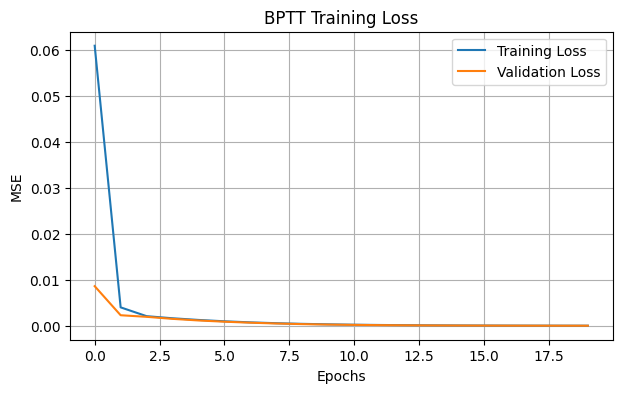

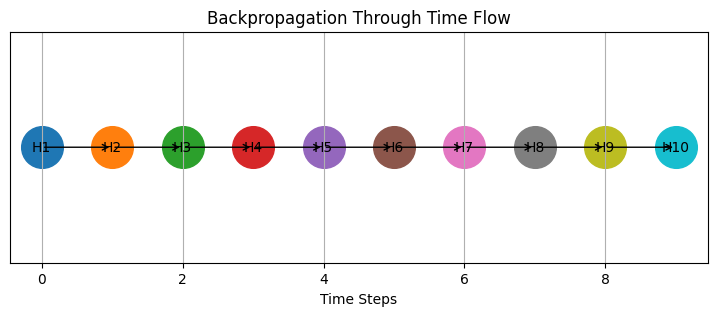

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Generate sequential dataset
np.random.seed(42)

X = np.sin(
    np.linspace(0, 50, 500)
)

# 2. Prepare sequences
def create_sequences(data, steps):

    X, y = [], []

    for i in range(len(data) - steps):

        X.append(data[i:i + steps])

        y.append(data[i + steps])

    return np.array(X), np.array(y)

steps = 10

X, y = create_sequences(X, steps)

X = X.reshape(-1, steps, 1)

# 3. Build RNN model
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(steps, 1)),

    tf.keras.layers.SimpleRNN(
        16,
        activation="tanh"
    ),

    tf.keras.layers.Dense(1)
])

# 4. Compile model
model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

# 5. Train model
history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# 6. Calculate gradients using GradientTape
sample_x = tf.convert_to_tensor(
    X[:1],
    dtype=tf.float32
)

sample_y = tf.convert_to_tensor(
    y[:1],
    dtype=tf.float32
)

with tf.GradientTape() as tape:

    prediction = model(sample_x, training=True)

    loss = tf.reduce_mean(
        tf.square(sample_y - prediction)
    )

gradients = tape.gradient(
    loss,
    model.trainable_variables
)

# 7. Display gradient values
print("\nBPTT GRADIENT ANALYSIS")

for variable, gradient in zip(
    model.trainable_variables,
    gradients
):

    print("\nVariable:", variable.name)

    print("Gradient Shape:", gradient.shape)

    print(
        "Gradient Norm:",
        tf.norm(gradient).numpy()
    )

# 8. Plot training loss
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("MSE")

plt.title("BPTT Training Loss")

plt.legend()
plt.grid()

plt.show()

# 9. Visualize BPTT flow
plt.figure(figsize=(9, 3))

for t in range(steps):

    plt.scatter(t, 1, s=900)

    plt.text(
        t, 1,
        f"H{t+1}",
        ha="center",
        va="center"
    )

    if t < steps - 1:

        plt.annotate(
            "",
            xy=(t+1, 1),
            xytext=(t, 1),
            arrowprops=dict(arrowstyle="->")
        )

plt.xlabel("Time Steps")
plt.title("Backpropagation Through Time Flow")

plt.yticks([])
plt.grid(axis="x")

plt.show()